# Olist · ETL e respostas às três perguntas de negócio

## Contexto e problema de negócio

A Olist é um marketplace brasileiro que conecta pequenas e médias lojas aos grandes canais de venda online. A loja vende, mas a entrega e a experiência do cliente dependem de uma operação logística compartilhada. Dois pontos afetam diretamente o resultado: **o atraso na entrega**, que pode derrubar a satisfação e a recompra, e **o custo do frete**, que encarece a compra e pode afastar o cliente.

O objetivo deste trabalho é identificar **onde esses dois problemas se concentram**, por estado e por categoria de produto, para orientar onde agir primeiro.

## Perguntas de investigação

| # | Pergunta | Por que importa para a decisão |
|---|---|---|
| 1 | Onde o atraso está associado a menor satisfação? | Mostra em quais estados e categorias melhorar o prazo traria mais ganho de nota. |
| 2 | Onde o frete pesa mais e como se relaciona com as medidas físicas do produto? | Mostra em quais categorias rever a política de frete e se peso e tamanho acompanham o custo. |
| 3 | Quais categorias relevantes são críticas nos três indicadores (atraso, frete e nota)? | Concentra o esforço em poucas categorias de alto faturamento, com ações combinadas. |

## A base de dados

**Fonte:** *Brazilian E-Commerce Public Dataset by Olist*, publicado pela própria Olist no Kaggle (licença CC BY-NC-SA 4.0). São dados reais de pedidos feitos entre **setembro de 2016 e outubro de 2018**: 99.441 pedidos, 96.096 clientes únicos, 27 UFs e 73 categorias de produto.

Usamos seis tabelas, em `data/raw/`, reduzidas às colunas necessárias para a análise:

| Tabela | Linhas | O que contém |
|---|---|---|
| pedidos | 99.441 | status, data da compra, entrega real e entrega prevista |
| clientes | 99.441 | cidade e UF do cliente |
| produtos | 32.951 | categoria, peso e dimensões |
| itens | 112.650 | produto, vendedor, preço e frete de cada item |
| pagamentos | 103.886 | forma de pagamento, parcelas e valor |
| avaliacao | 99.224 | nota de 1 a 5 dada ao pedido |

**Por que a base é adequada e confiável:**

- **É real:** são transações de um marketplace em operação, não dados simulados.
- **Responde às três perguntas:** tem as datas de entrega real e prevista (atraso), o preço e o frete de cada item (peso do frete), as medidas físicas dos produtos e a nota do cliente.
- **Tem volume e cobertura nacional:** quase 100 mil pedidos em todos os estados permitem comparar estados e categorias com amostras suficientes.
- **É pública e anonimizada:** os identificadores são códigos, sem nome, CPF ou endereço completo dos clientes.
- **É amplamente usada** em estudos e cursos de análise de dados, o que facilita comparar resultados.
- **Tem limitações conhecidas, tratadas na seção 2:** datas de entrega ausentes, produtos sem categoria, pesos zerados e datas de envio com erro em 2020.

## Organização do notebook

O notebook regenera as tabelas tratadas em `saida_analise/tratados/` e confere cada uma com as versões em `data/cleansed/`. Os resultados das três perguntas são gravados em `data/analytics/`.

## 1. Leitura e auditoria das tabelas originais

In [1]:
from pathlib import Path
import pandas as pd

dados = Path("data")
saida = Path("saida_analise")
analytics = dados / "analytics"
analytics.mkdir(exist_ok=True)
chaves = {
    "pedidos": ["order_id"], "clientes": ["customer_id"],
    "produtos": ["product_id"], "itens": ["order_id", "order_item_id"],
    "pagamentos": ["order_id", "payment_sequential"], "avaliacao": ["order_id"]
}
tabelas = {}
auditoria = []
for nome, chave in chaves.items():
    tabela = pd.read_csv(dados / "raw" / f"tabela_{nome}.csv", sep=";")
    tabelas[nome] = tabela
    auditoria.append([nome, len(tabela), tabela.isna().sum().sum(),
                      tabela.duplicated().sum(), tabela.duplicated(chave).sum()])
    assert tabela[chave].notna().all().all(), nome
    if nome != "avaliacao":
        assert not tabela.duplicated(chave).any(), nome
print(pd.DataFrame(auditoria, columns=["tabela", "linhas", "células nulas",
                                      "linhas repetidas", "chaves repetidas"]).to_string(index=False))

    tabela  linhas  células nulas  linhas repetidas  chaves repetidas
   pedidos   99441           2965                 0                 0
  clientes   99441              0                 0                 0
  produtos   32951            618                 0                 0
     itens  112650              0                 0                 0
pagamentos  103886              0                 0                 0
 avaliacao   99224              0               349               551


## 2. Tratamento e conferência

Preservamos avaliações repetidas porque o extrato contém apenas pedido e nota. Frete zero é um valor observado. Pesos zero e parcelas incompatíveis com cartão ficam sinalizados. Datas de entrega ausentes permanecem ausentes. A marca de data de envio identifica a anomalia de 2020 documentada nesta edição da base.

In [2]:
ped = tabelas["pedidos"]
cli = tabelas["clientes"]
prod = tabelas["produtos"]
itens = tabelas["itens"]
pag = tabelas["pagamentos"]
av = tabelas["avaliacao"]

for coluna in ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]:
    ped[coluna] = pd.to_datetime(ped[coluna], errors="raise")
entregue = ped.order_status.eq("delivered")
ped["entregue_sem_data_entrega"] = entregue & ped.order_delivered_customer_date.isna()
ped["nao_entregue_com_data_entrega"] = ~entregue & ped.order_delivered_customer_date.notna()

cli["customer_city"] = cli.customer_city.str.strip().str.lower()
cli["customer_state"] = cli.customer_state.str.strip().str.upper()
prod["product_category_name"] = prod.product_category_name.fillna("nao_definido")
prod["peso_inconsistente"] = prod.product_weight_g.eq(0)
prod.loc[prod.peso_inconsistente, "product_weight_g"] = float("nan")
itens["shipping_limit_date"] = pd.to_datetime(itens.shipping_limit_date)
assert itens.price.gt(0).all() and itens.freight_value.ge(0).all()
itens["total_value"] = itens.price + itens.freight_value
itens["frete_zero"] = itens.freight_value.eq(0)
itens["data_envio_inconsistente"] = itens.shipping_limit_date.dt.year.eq(2020)

pag["pagamento_valor_zero"] = pag.payment_value.eq(0)
pag["parcelas_inconsistentes"] = pag.payment_type.eq("credit_card") & pag.payment_installments.eq(0)
pag["payment_installments"] = pag.payment_installments.astype("Int64").mask(pag.parcelas_inconsistentes)
pag["payment_type"] = pag.payment_type.replace("not_defined", pd.NA)
assert av.review_score.isin(range(1, 6)).all()
av["pedido_com_multiplas_avaliacoes"] = av.duplicated("order_id", keep=False)
av["pedido_nota_repetidos"] = av.duplicated(["order_id", "review_score"], keep=False)

tratados = saida / "tratados"
tratados.mkdir(parents=True, exist_ok=True)
for nome, tabela in tabelas.items():
    arquivo = f"tabela_{nome}.csv"
    tabela.to_csv(tratados / arquivo, sep=";", index=False)
    esperado = pd.read_csv(dados / "cleansed" / arquivo, sep=";")
    obtido = pd.read_csv(tratados / arquivo, sep=";")
    pd.testing.assert_frame_equal(obtido, esperado)
print("As seis tabelas regeneradas conferem com os CSVs tratados.")

As seis tabelas regeneradas conferem com os CSVs tratados.


## 3. População e unidades de análise

Usamos pedidos entregues com datas real e prevista conhecidas nas três perguntas. A unidade de entrega é o pedido. A nota do pedido é a média de suas avaliações disponíveis. Para a análise por categoria, um pedido conta uma vez em cada categoria comprada. Os totais por categoria podem, portanto, superar o número global de pedidos. A nota descreve a experiência com o pedido inteiro. Valor de mercadorias é a soma dos preços dos itens, em reais, sem frete.

In [3]:
elegivel = entregue & ped.order_delivered_customer_date.notna() & ped.order_estimated_delivery_date.notna()
pedidos = ped.loc[elegivel].merge(cli[["customer_id", "customer_state"]], how="left",
                                  on="customer_id", validate="many_to_one")
assert pedidos.customer_state.notna().all()
pedidos["atrasado"] = (pedidos.order_delivered_customer_date.dt.normalize()
                       > pedidos.order_estimated_delivery_date.dt.normalize())
notas = av.groupby("order_id").review_score.mean().rename("nota")
pedidos = pedidos.join(notas, on="order_id", validate="one_to_one")
vendas = itens.merge(pedidos[["order_id", "atrasado", "nota"]], on="order_id", validate="many_to_one")
vendas = vendas.merge(prod, on="product_id", how="left", validate="many_to_one")
assert vendas.product_category_name.notna().all()
cat = "product_category_name"
pc = vendas[["order_id", cat, "atrasado", "nota"]].drop_duplicates(["order_id", cat])
print("Pedidos originais / elegíveis / avaliados / com itens:",
      len(ped), len(pedidos), pedidos.nota.count(), vendas.order_id.nunique())
print(pedidos.groupby("atrasado").nota.agg(["size", "count", "mean"]))

Pedidos originais / elegíveis / avaliados / com itens: 99441 96470 95824 96470
           size  count      mean
atrasado                        
False     89936  89443  4.290589
True       6534   6381  2.271823


## 4. Estatística descritiva da população

Resumo das principais medidas antes das perguntas. Preço e frete são medidos por item vendido; nota e prazos, por pedido elegível. A assimetria indica cauda longa: valores positivos mostram poucos casos muito altos, e negativos, poucos casos muito baixos. Em seguida, mostramos a taxa de atraso e a distribuição das notas das avaliações no prazo e em atraso.

In [4]:
medidas = {
    "Preço do item (R$)": vendas.price,
    "Frete do item (R$)": vendas.freight_value,
    "Frete / preço do item (%)": 100 * vendas.freight_value / vendas.price,
    "Nota do pedido (1 a 5)": pedidos.nota,
    "Dias da compra à entrega": (pedidos.order_delivered_customer_date
                                 - pedidos.order_purchase_timestamp).dt.total_seconds() / 86400,
    "Dias em relação ao previsto (+ = atraso)": (pedidos.order_delivered_customer_date.dt.normalize()
                                                 - pedidos.order_estimated_delivery_date.dt.normalize()).dt.days,
}
resumo_estatistico = pd.DataFrame({nome: serie.describe() for nome, serie in medidas.items()}).T
resumo_estatistico["assimetria"] = [serie.skew() for serie in medidas.values()]
resumo_estatistico.columns = ["n", "média", "desvio padrão", "mínimo", "25%", "mediana", "75%", "máximo", "assimetria"]
resumo_estatistico["n"] = resumo_estatistico["n"].astype(int)
print(resumo_estatistico.round(2).to_string())

notas_avaliacoes = av.merge(pedidos[["order_id", "atrasado"]], on="order_id", validate="many_to_one")
distribuicao = pd.crosstab(notas_avaliacoes.review_score, notas_avaliacoes.atrasado, normalize="columns").mul(100)
distribuicao.columns = ["no prazo (%)", "em atraso (%)"]
distribuicao["todas (%)"] = notas_avaliacoes.review_score.value_counts(normalize=True).mul(100)
distribuicao.index.name = "nota"
print(f"\nTaxa de atraso: {100 * pedidos.atrasado.mean():.2f}% dos {len(pedidos)} pedidos elegíveis")
print("Distribuição das notas das avaliações:")
print(distribuicao.round(1).to_string())

                                               n   média  desvio padrão  mínimo    25%  mediana     75%   máximo  assimetria
Preço do item (R$)                        110189  119.98         182.30    0.85  39.90    74.90  134.17  6735.00        8.03
Frete do item (R$)                        110189   19.95          15.70    0.00  13.08    16.26   21.15   409.68        5.66
Frete / preço do item (%)                 110189   32.08          34.78    0.00  13.45    23.18   39.33  2623.53       11.77
Nota do pedido (1 a 5)                     95824    4.16           1.28    1.00   4.00     5.00    5.00     5.00       -1.48
Dias da compra à entrega                   96470   12.56           9.55    0.53   6.77    10.22   15.72   209.63        3.83
Dias em relação ao previsto (+ = atraso)   96470  -11.88          10.18 -147.00 -17.00   -12.00   -7.00   188.00        2.02

Taxa de atraso: 6.77% dos 96470 pedidos elegíveis
Distribuição das notas das avaliações:
      no prazo (%)  em atraso (%)  

**Leitura do resumo.**

- **Preço e frete têm cauda longa.** O preço médio do item é R$ 119,98, mas a mediana é R$ 74,90: poucos itens caros puxam a média para cima. Por isso, nas perguntas usamos somas por categoria e medianas por faixa, e não médias simples de item.
- **O frete pesa mais nos itens baratos.** A mediana do frete por item é R$ 16,26, cerca de 23% do preço. No agregado, o frete equivale a 16,6% do valor vendido, porque os itens caros diluem o frete.
- **As notas se concentram nos extremos.** 59,2% das avaliações dão nota 5 e 9,8% dão nota 1, com poucos casos intermediários. A média dos pedidos é 4,16 e a mediana, 5.
- **A data prevista costuma ter folga.** A entrega leva 10,2 dias na mediana, e o pedido típico chega 12 dias antes do previsto. Ainda assim, 6,77% dos pedidos atrasam.
- **O atraso muda o perfil das notas.** Entre as avaliações de pedidos atrasados, 53,7% são nota 1, contra 6,6% entre os entregues no prazo. Esse contraste motiva a Pergunta 1.

## Pergunta 1 · Onde o atraso está associado a menor satisfação?

Diferença em pontos = nota média no prazo menos nota média em atraso. Cada média divide a soma das notas dos pedidos avaliados pelo número de pedidos avaliados naquele grupo. Ordenamos grupos com pelo menos 30 pedidos avaliados em cada condição para reduzir a influência de amostras muito pequenas. O CSV também mostra os demais grupos e os pedidos sem nota entram na contagem de cobertura.

In [5]:
def comparar_notas(dados_grupo, chave):
    resumo = dados_grupo.groupby([chave, "atrasado"]).nota.agg(
        pedidos="size", avaliados="count", media="mean").unstack("atrasado")
    resumo.columns = [f"{medida}_{'atraso' if atraso else 'prazo'}" for medida, atraso in resumo.columns]
    resumo["diferenca_pontos"] = resumo.media_prazo - resumo.media_atraso
    resumo["base_suficiente"] = (resumo.avaliados_prazo.ge(30) & resumo.avaliados_atraso.ge(30))
    return resumo.sort_values("diferenca_pontos", ascending=False)

for chave, base in [("customer_state", pedidos), (cat, pc)]:
    resumo = comparar_notas(base, chave)
    resumo.to_csv(analytics / f"pergunta_1_{chave}.csv")
    print(resumo[resumo.base_suficiente].head(5).round(2).to_string())

                pedidos_prazo  pedidos_atraso  avaliados_prazo  avaliados_atraso  media_prazo  media_atraso  diferenca_pontos  base_suficiente
customer_state                                                                                                                                
RN                        430              44              428                43         4.39          1.77              2.62             True
RJ                      10855            1495            10755              1456         4.24          1.91              2.33             True
SE                        284              51              284                50         4.25          1.94              2.31             True
DF                       1962             118             1952               118         4.26          1.97              2.29             True
PE                       1440             153             1430               149         4.30          2.03              2.26             True

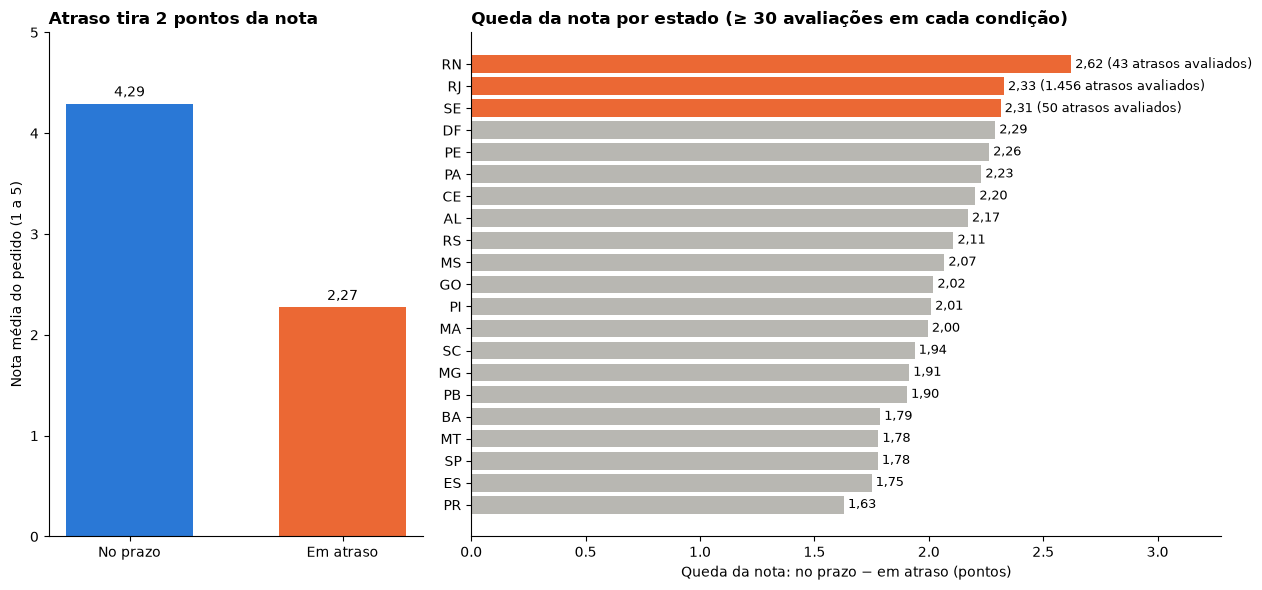

In [6]:
import matplotlib.pyplot as plt

PRAZO, ATRASO, NEUTRO, GUIA = "#2a78d6", "#eb6834", "#b8b7b2", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "axes.titleweight": "bold"})
virgula = lambda valor, casas=2: f"{valor:.{casas}f}".replace(".", ",")
milhar = lambda valor: f"{valor:,.0f}".replace(",", ".")
legivel = lambda nomes: [str(nome).replace("_", " ") for nome in nomes]

geral = pedidos.groupby("atrasado").nota.mean()
uf = comparar_notas(pedidos, "customer_state").query("base_suficiente").sort_values("diferenca_pontos")
destaque = uf.index[-3:]

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1, 2]})
barras = a.bar(["No prazo", "Em atraso"], geral.values, color=[PRAZO, ATRASO], width=0.6)
a.bar_label(barras, labels=[virgula(v) for v in geral.values], padding=3)
a.set(ylim=(0, 5), ylabel="Nota média do pedido (1 a 5)", title="Atraso tira 2 pontos da nota")

barras = b.barh(uf.index, uf.diferenca_pontos, color=[ATRASO if e in destaque else NEUTRO for e in uf.index])
b.bar_label(barras, padding=3, fontsize=9,
            labels=[f"{virgula(d)} ({milhar(n)} atrasos avaliados)" if e in destaque else virgula(d)
                    for e, d, n in zip(uf.index, uf.diferenca_pontos, uf.avaliados_atraso)])
b.set(xlabel="Queda da nota: no prazo − em atraso (pontos)", xlim=(0, uf.diferenca_pontos.max() * 1.25),
      title="Queda da nota por estado (≥ 30 avaliações em cada condição)")
fig.tight_layout()
plt.show()

## Pergunta 2 · Onde o frete pesa mais e como se relaciona com as medidas físicas?

Frete proporcional da categoria = 100 × soma dos fretes dos itens / soma dos preços dos mesmos itens. Incluímos itens com frete zero. Exibimos categorias identificadas com pelo menos 100 pedidos elegíveis. Para a associação física, calculamos a correlação de Spearman por item vendido, usando os pares com medidas disponíveis. Comparamos frete em reais e frete/preço para distinguir as duas relações. São associações descritivas, sujeitas a diferenças de preço, rota e categoria.

In [7]:
comercial = vendas.groupby(cat).agg(itens=("order_id", "size"), pedidos=("order_id", "nunique"),
                                    valor_mercadorias=("price", "sum"), frete=("freight_value", "sum"))
comercial["frete_pct"] = 100 * comercial.frete / comercial.valor_mercadorias
comercial.sort_values("frete_pct", ascending=False).to_csv(analytics / "pergunta_2_categorias.csv")
identificadas = comercial[comercial.index != "nao_definido"]
print(identificadas[identificadas.pedidos.ge(100)].nlargest(5, "frete_pct").round(2).to_string())

vendas["volume_cm3"] = vendas.product_length_cm * vendas.product_width_cm * vendas.product_height_cm
vendas["frete_preco"] = vendas.freight_value / vendas.price
associacoes = []
for medida in ["product_weight_g", "volume_cm3", "product_length_cm", "product_width_cm", "product_height_cm"]:
    pares = vendas[[medida, "freight_value", "frete_preco"]].dropna()
    ranks = pares.rank()
    associacoes.append([medida, len(pares), ranks[medida].corr(ranks.freight_value),
                        ranks[medida].corr(ranks.frete_preco)])
fisico = pd.DataFrame(associacoes, columns=["medida", "itens_validos", "rho_frete_reais", "rho_frete_preco"])
print(fisico.round(3).to_string(index=False))
fisico.to_csv(analytics / "pergunta_2_medidas.csv", index=False)

                         itens  pedidos  valor_mercadorias     frete  frete_pct
product_category_name                                                          
artigos_de_natal           150      125            8737.84   3190.91      36.52
sinalizacao_e_seguranca    197      138           21315.05   6477.54      30.39
eletronicos               2729     2517          155043.93  45679.16      29.46
alimentos_bebidas          269      221           14942.88   4394.89      29.41
moveis_sala                495      414           67350.70  17694.37      26.27
           medida  itens_validos  rho_frete_reais  rho_frete_preco
 product_weight_g         110163            0.446           -0.271
       volume_cm3         110171            0.368           -0.180
product_length_cm         110171            0.283           -0.101
 product_width_cm         110171            0.273           -0.117
product_height_cm         110171            0.282           -0.166


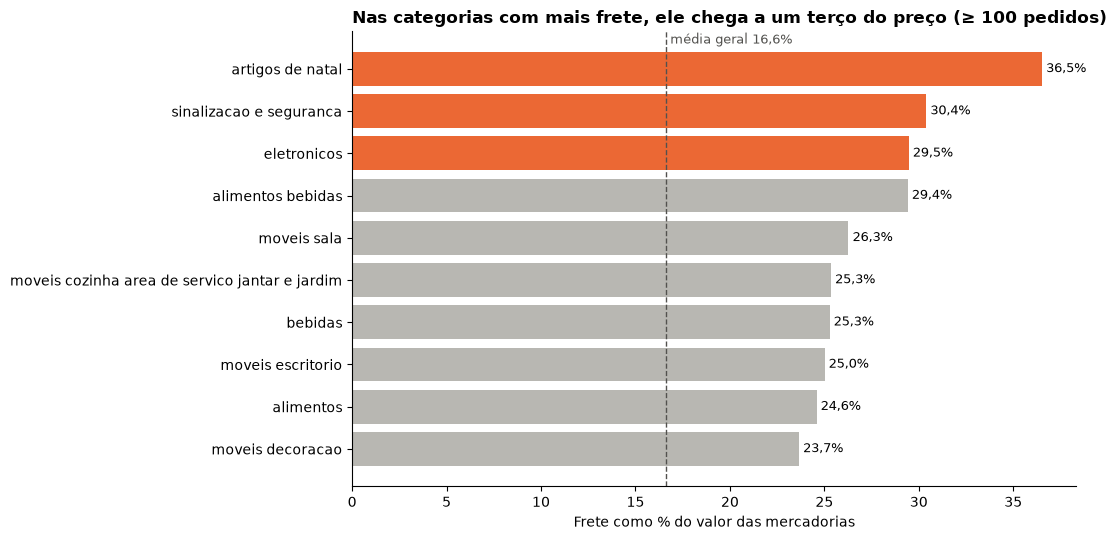

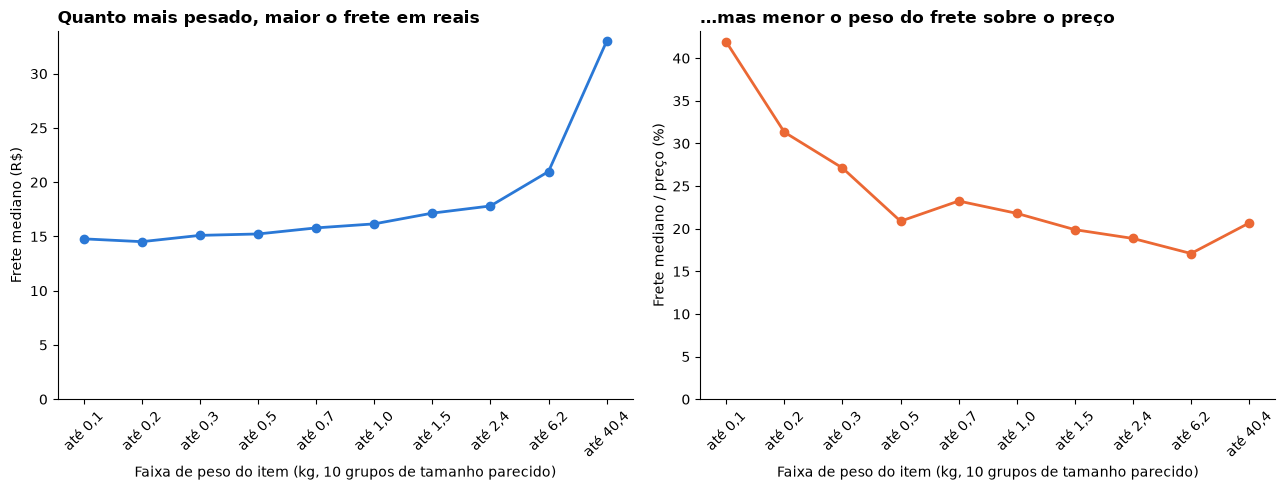

In [8]:
top_frete = identificadas[identificadas.pedidos.ge(100)].nlargest(10, "frete_pct").sort_values("frete_pct")
frete_geral = 100 * vendas.freight_value.sum() / vendas.price.sum()

fig, ax = plt.subplots(figsize=(11, 5.5))
barras = ax.barh(legivel(top_frete.index), top_frete.frete_pct,
                 color=[ATRASO if i >= len(top_frete) - 3 else NEUTRO for i in range(len(top_frete))])
ax.bar_label(barras, labels=[virgula(v, 1) + "%" for v in top_frete.frete_pct], padding=3, fontsize=9)
ax.axvline(frete_geral, color=GUIA, linestyle="--", linewidth=1)
ax.text(frete_geral, len(top_frete) - 0.4, f" média geral {virgula(frete_geral, 1)}%", color=GUIA, fontsize=9)
ax.set(xlabel="Frete como % do valor das mercadorias",
       title="Nas categorias com mais frete, ele chega a um terço do preço (≥ 100 pedidos)")
fig.tight_layout()
plt.show()

# Mediana por faixa de peso: mesma leitura por postos da correlação de Spearman acima
faixas = pd.qcut(vendas.product_weight_g, 10, duplicates="drop")
por_peso = vendas.groupby(faixas, observed=True).agg(frete=("freight_value", "median"),
                                                     frete_preco=("frete_preco", "median"))
rotulos = [f"até {virgula(faixa.right / 1000, 1)}" for faixa in por_peso.index]

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
a.plot(rotulos, por_peso.frete, marker="o", color=PRAZO, linewidth=2)
a.set(ylabel="Frete mediano (R$)", title="Quanto mais pesado, maior o frete em reais", ylim=(0, None))
b.plot(rotulos, 100 * por_peso.frete_preco, marker="o", color=ATRASO, linewidth=2)
b.set(ylabel="Frete mediano / preço (%)", title="…mas menor o peso do frete sobre o preço", ylim=(0, None))
for eixo in (a, b):
    eixo.set_xlabel("Faixa de peso do item (kg, 10 grupos de tamanho parecido)")
    eixo.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

## Pergunta 3 · Quais categorias relevantes são críticas nos três indicadores?

Definimos relevância como as dez categorias identificadas com maior valor de mercadorias no recorte. Uma categoria é crítica quando, simultaneamente, sua taxa de atraso e seu frete proporcional superam as referências globais e sua nota média fica abaixo da média global. Taxa de atraso divide pedidos atrasados pelos pedidos elegíveis do grupo. A nota usa apenas os pedidos avaliados. As referências globais contam cada pedido uma vez e incluem todas as categorias no cálculo monetário.

In [9]:
referencia = pd.Series({
    "atraso_pct": 100 * pedidos.atrasado.mean(),
    "frete_pct": 100 * vendas.freight_value.sum() / vendas.price.sum(),
    "nota_media": pedidos.nota.mean()
})
operacao = pc.groupby(cat).agg(atrasados=("atrasado", "sum"), avaliados=("nota", "count"),
                               nota_media=("nota", "mean"))
ranking = identificadas.nlargest(10, "valor_mercadorias").join(operacao)
ranking["atraso_pct"] = 100 * ranking.atrasados / ranking.pedidos
ranking["critica"] = (ranking.atraso_pct.gt(referencia.atraso_pct)
                      & ranking.frete_pct.gt(referencia.frete_pct)
                      & ranking.nota_media.lt(referencia.nota_media))
print("Referências globais:", referencia.round(3).to_dict())
print(ranking.round(2).to_string())
ranking.to_csv(analytics / "pergunta_3_top10.csv")

Referências globais: {'atraso_pct': 6.773, 'frete_pct': 16.627, 'nota_media': 4.156}
                        itens  pedidos  valor_mercadorias      frete  frete_pct  atrasados  avaliados  nota_media  atraso_pct  critica
product_category_name                                                                                                                 
beleza_saude             9465     8647         1233131.72  178957.81      14.51        649       8601        4.23        7.51    False
relogios_presentes       5857     5493         1165898.98   98118.00       8.42        406       5452        4.12        7.39    False
cama_mesa_banho         10953     9272         1023434.76  201774.50      19.72        689       9177        4.00        7.43     True
esporte_lazer            8430     7529          954673.55  163389.36      17.11        495       7485        4.23        6.57    False
informatica_acessorios   7643     6529          888613.62  143990.03      16.20        417       6498    

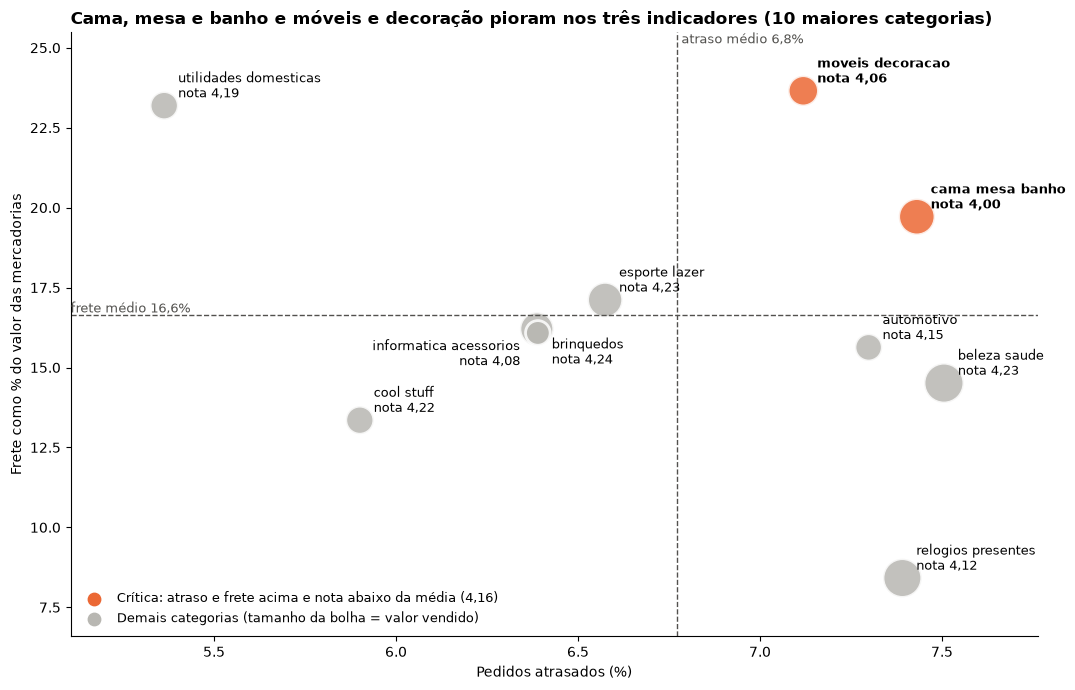

In [10]:
deslocamento = {"brinquedos": (10, -22), "informatica_acessorios": (-12, -26)}

fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(ranking.atraso_pct, ranking.frete_pct, s=ranking.valor_mercadorias / 1500,
           color=ranking.critica.map({True: ATRASO, False: NEUTRO}), alpha=0.85, edgecolor="white", linewidth=2)
for nome, linha in ranking.iterrows():
    dx, dy = deslocamento.get(nome, (10, 6))
    ax.annotate(f"{nome.replace('_', ' ')}\nnota {virgula(linha.nota_media)}", (linha.atraso_pct, linha.frete_pct),
                xytext=(dx, dy), textcoords="offset points", fontsize=9, ha="right" if dx < 0 else "left",
                fontweight="bold" if linha.critica else "normal")
ax.margins(0.12)
ax.axvline(referencia.atraso_pct, color=GUIA, linestyle="--", linewidth=1)
ax.axhline(referencia.frete_pct, color=GUIA, linestyle="--", linewidth=1)
ax.text(referencia.atraso_pct, ax.get_ylim()[1], f" atraso médio {virgula(referencia.atraso_pct, 1)}%",
        va="top", fontsize=9, color=GUIA)
ax.text(ax.get_xlim()[0], referencia.frete_pct, f"frete médio {virgula(referencia.frete_pct, 1)}%",
        va="bottom", fontsize=9, color=GUIA)
ax.scatter([], [], color=ATRASO, s=80,
           label=f"Crítica: atraso e frete acima e nota abaixo da média ({virgula(referencia.nota_media)})")
ax.scatter([], [], color=NEUTRO, s=80, label="Demais categorias (tamanho da bolha = valor vendido)")
ax.legend(loc="lower left", frameon=False, fontsize=9)
ax.set(xlabel="Pedidos atrasados (%)", ylabel="Frete como % do valor das mercadorias",
       title="Cama, mesa e banho e móveis e decoração pioram nos três indicadores (10 maiores categorias)")
fig.tight_layout()
plt.show()

## Respostas

1. **Atraso e satisfação.** Entre grupos com pelo menos 30 avaliações em cada condição, as maiores quedas de nota aparecem no RN (2,62 pontos), RJ (2,33) e SE (2,31). Nas categorias, destacam-se instrumentos musicais (2,51), áudio (2,39) e brinquedos (2,24). O RJ reúne 1.456 pedidos atrasados avaliados, contra 43 no RN. A diferença observada é uma associação e o tamanho das amostras importa para interpretar a ordem.

2. **Frete.** Entre categorias com pelo menos 100 pedidos, artigos de Natal lidera (36,52%), seguida de sinalização e segurança (30,39%) e eletrônicos (29,46%). Peso e volume têm associação positiva com o frete em reais e negativa com a proporção frete/preço neste conjunto de itens. O preço do produto entra no denominador, e as correlações agregadas não isolam um efeito de peso ou volume.

3. **Prioridade comercial.** Entre as dez categorias de maior valor vendido, cama, mesa e banho e móveis e decoração atendem aos três critérios simultaneamente. A primeira tem maior valor vendido entre as duas e 689 pedidos atrasados. Na segunda, o frete equivale a 23,65% do valor das mercadorias, ante 16,63% no conjunto.

## Recomendações

1. **Atacar o atraso onde ele tem mais volume.** Um pedido atrasado recebe, em média, 2 pontos a menos (4,29 → 2,27). O RJ combina queda alta (2,33 pontos) com o maior número de atrasos avaliados (1.456). Recomendamos revisar transportadoras e rotas para o RJ e calibrar o prazo estimado informado ao cliente. RN e SE têm a maior queda, mas com poucos casos: acompanhar antes de agir.

2. **Rever a política de frete nas categorias em que ele pesa mais.** Em artigos de Natal, sinalização e segurança e eletrônicos, o frete passa de 29% do valor da compra, contra 16,6% na média. Itens leves pagam proporcionalmente mais frete. Recomendamos testar frete grátis acima de um valor mínimo ou incentivo a compras em conjunto nessas categorias.

3. **Priorizar cama, mesa e banho e móveis e decoração.** São as únicas, entre as dez categorias que mais vendem, com atraso e frete acima da média e nota abaixo dela. Recomendamos um piloto de prioridade logística e renegociação de frete, medindo atraso, frete e nota antes e depois.

As relações mostradas são associações, não causa e efeito. Por isso, as ações acima devem começar como pilotos com métricas de acompanhamento.